# AED 02 — Conjunto de baterías

Análisis exploratorio de las **228 celdas juntas**: cobertura, degradación por
condición, variabilidad entre réplicas y qué implican los datos para el
diseño experimental (partición por celda y por condición, corte temporal).

**Dataset:** Luh & Blank (2024), RADAR4KIT v2, *result data*,
DOI [10.35097/1969](https://doi.org/10.35097/1969).
Trabaja sobre `../datos/consolidado_capacidad.csv` (una fila por celda y CU,
construido con `build_datos.py` desde las filas de check-up).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path("..")
cons = pd.read_csv(REPO / "datos" / "consolidado_capacidad.csv")
print("forma:", cons.shape)
print("columnas:", list(cons.columns))
print(cons.head(3).to_string())
print()
print("celdas:", cons["cell_id"].nunique(),
      "| condiciones:", cons["condicion"].nunique(),
      "| CU max:", cons["cu"].max())

forma: (4006, 19)
columnas: ['cell_id', 'condicion', 'replica', 'slave', 'slot', 'cu', 'timestamp_s', 'num_cycles_op', 'q_chg_Ah', 'q_dischg_Ah', 'q_Ah', 'soh_cap', 'soh_nominal', 'age_type', 'age_temp', 'age_soc', 'age_chg_rate', 'age_dischg_rate', 'age_profile']
  cell_id  condicion  replica  slave  slot  cu   timestamp_s  num_cycles_op  q_chg_Ah  q_dischg_Ah      q_Ah    soh_cap  soh_nominal  age_type  age_temp  age_soc  age_chg_rate  age_dischg_rate  age_profile
0  P001_1          1        1      1    10   0  1.665626e+09              0  2.973577     2.967744  2.970661  98.044061    99.022017       1.0       0.0     10.0           0.0              0.0          0.0
1  P001_1          1        1      1    10   1  1.666233e+09              0  2.981291     2.962058  2.971675  98.111621    99.055817       1.0       0.0     10.0           0.0              0.0          0.0
2  P001_1          1        1      1    10   2  1.668032e+09              0  2.967676     2.951028  2.959352  97.2901

/home/hatch/workspace/venvs/baterias/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## 1. Cobertura: celdas, condiciones y check-ups

76 condiciones × 3 réplicas = 228 celdas. Cada celda tiene un número distinto
de check-ups: las que envejecen rápido llegan a menos CU.

In [2]:
por_celda = cons.groupby("cell_id").agg(
    cu_max=("cu", "max"), n_cu=("cu", "count"),
    soh_ini=("soh_nominal", "first"), soh_fin=("soh_nominal", "last"),
    cond=("condicion", "first"), tipo=("age_type", "first"),
    temp=("age_temp", "first"))
print(por_celda["n_cu"].describe().round(2).to_string())
print()
print("celdas con menos de 6 CU (no llegan a la historia minima del diseno):",
      (por_celda["n_cu"] < 6).sum())
print("celdas con menos de 8 CU (no llegan al corte C1):",
      (por_celda["n_cu"] < 8).sum())
print()
print(por_celda.nsmallest(8, "n_cu")[["cond", "tipo", "temp", "n_cu", "soh_fin"]].round(1).to_string())

count    228.00
mean      17.57
std       10.45
min        2.00
25%        7.00
50%       16.00
75%       29.00
max       29.00

celdas con menos de 6 CU (no llegan a la historia minima del diseno): 48
celdas con menos de 8 CU (no llegan al corte C1): 64

         cond  tipo  temp  n_cu  soh_fin
cell_id                                 
P024_1     24   2.0   0.0     2     86.9
P024_3     24   2.0   0.0     2     86.5
P044_2     44   2.0  25.0     2     89.6
P019_1     19   2.0   0.0     3     65.4
P019_2     19   2.0   0.0     3     65.5
P019_3     19   2.0   0.0     3     66.5
P020_1     20   2.0   0.0     3     66.9
P020_2     20   2.0   0.0     3     66.5


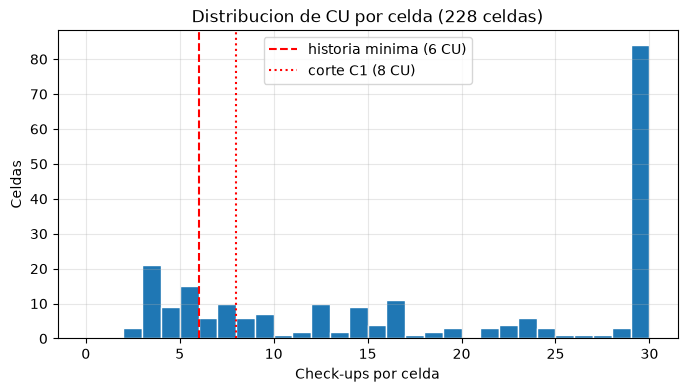

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(por_celda["n_cu"], bins=range(0, 31), edgecolor="white")
ax.axvline(6, color="r", ls="--", label="historia minima (6 CU)")
ax.axvline(8, color="r", ls=":", label="corte C1 (8 CU)")
ax.set_xlabel("Check-ups por celda")
ax.set_ylabel("Celdas")
ax.set_title("Distribucion de CU por celda (228 celdas)")
ax.legend(); ax.grid(True, alpha=0.3)
plt.show()

## 2. Verificación de la fuga a escala

El AED 01 mostró la fuga en dos celdas. Aquí se verifica en una muestra del
conjunto completo, siempre sobre filas de check-up.

In [4]:
import glob, random
random.seed(7)
files = sorted(glob.glob(str(REPO / "dataset" / "extraido" / "cell_eocv2" / "cell_eocv2_P0*.csv")))
muestra = random.sample(files, 24)
rows = []
for f in muestra:
    d = pd.read_csv(f, sep=";")
    cu = d[(d["cyc_condition"] == 2) & d["soh_cap"].notna()]
    rows.append(cu[["cap_aged_est_Ah", "soh_cap"]])
m = pd.concat(rows)
print("filas CU en la muestra:", len(m), "| celdas:", len(muestra))
print("correlacion soh_cap vs cap_aged_est_Ah:",
      round(m["soh_cap"].corr(m["cap_aged_est_Ah"]), 12))
a, b = np.polyfit(m["cap_aged_est_Ah"], m["soh_cap"], 1)
print("ajuste: soh_cap = %.4f * cap %+.4f" % (a, b))
err = ((m["cap_aged_est_Ah"] - 1.5) / 1.5 * 100 - m["soh_cap"]).abs().max()
print("desviacion maxima de (cap - 1.5)/1.5*100: %.2e" % err)
print("Conclusion: la fuga se confirma a escala. cap_aged_est_Ah queda fuera de las variables.")

filas CU en la muestra: 852 | celdas: 24
correlacion soh_cap vs cap_aged_est_Ah: 0.999999999999
ajuste: soh_cap = 66.6667 * cap -100.0000
desviacion maxima de (cap - 1.5)/1.5*100: 3.53e-05
Conclusion: la fuga se confirma a escala. cap_aged_est_Ah queda fuera de las variables.


/tmp/ipykernel_10750/4285008844.py:10: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  m = pd.concat(rows)


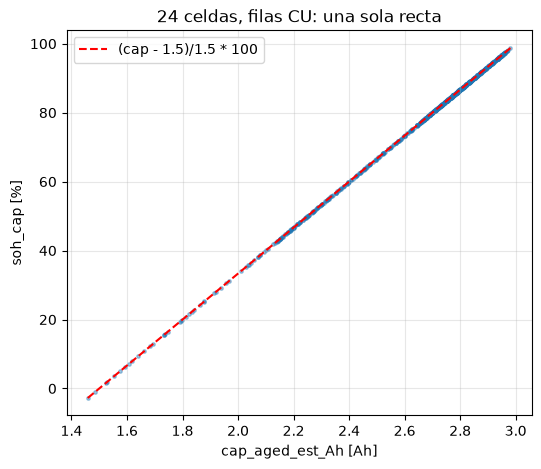

In [5]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(m["cap_aged_est_Ah"], m["soh_cap"], s=6, alpha=0.4)
xs = np.linspace(m["cap_aged_est_Ah"].min(), m["cap_aged_est_Ah"].max(), 10)
ax.plot(xs, (xs - 1.5) / 1.5 * 100, "r--", label="(cap - 1.5)/1.5 * 100")
ax.set_xlabel("cap_aged_est_Ah [Ah]")
ax.set_ylabel("soh_cap [%]")
ax.set_title("24 celdas, filas CU: una sola recta")
ax.legend(); ax.grid(True, alpha=0.3)
plt.show()

## 3. SoH final y degradación

¿Cuánto bajó cada celda? ¿Cuántas cruzaron los umbrales del diseño
(80 % y 50 % nominales)?

In [6]:
fin = por_celda["soh_fin"]
print("SoH nominal final: media %.1f %%, mediana %.1f %%, min %.1f %%, max %.1f %%"
      % (fin.mean(), fin.median(), fin.min(), fin.max()))
print("celdas bajo 80%% nominal al final:", (fin < 80).sum(), "de", len(fin))
print("celdas bajo 50%% nominal al final:", (fin < 50).sum(), "de", len(fin))
print("celdas que nunca bajan de 80%%:", (fin >= 80).sum())
por_celda["caida_por_cu"] = (por_celda["soh_ini"] - por_celda["soh_fin"]) / por_celda["n_cu"]
print()
print("caida de SoH nominal por CU (puntos/CU):")
print(por_celda["caida_por_cu"].describe().round(3).to_string())

SoH nominal final: media 70.9 %, mediana 70.7 %, min 32.4 %, max 92.4 %
celdas bajo 80%% nominal al final: 163 de 228
celdas bajo 50%% nominal al final: 15 de 228
celdas que nunca bajan de 80%%: 65

caida de SoH nominal por CU (puntos/CU):
count    228.000
mean       3.030
std        3.016
min        0.219
25%        0.753
50%        2.001
75%        4.301
max       12.362


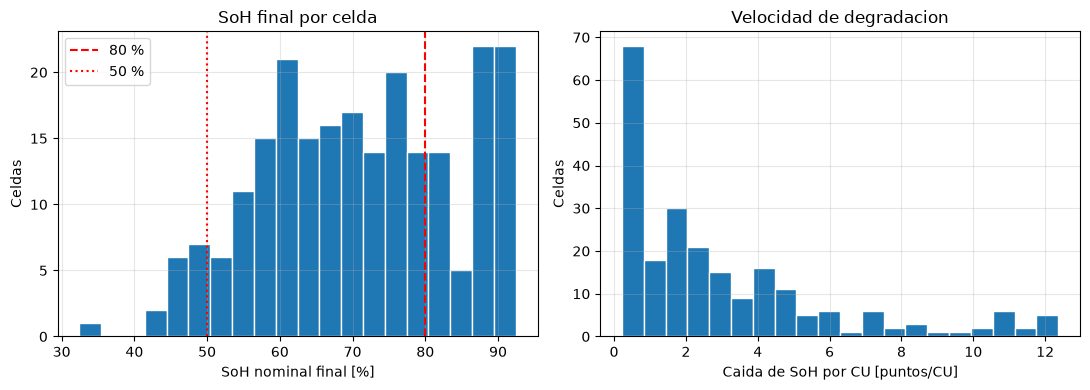

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(fin, bins=20, edgecolor="white")
axes[0].axvline(80, color="r", ls="--", label="80 %")
axes[0].axvline(50, color="r", ls=":", label="50 %")
axes[0].set_xlabel("SoH nominal final [%]")
axes[0].set_ylabel("Celdas")
axes[0].set_title("SoH final por celda")
axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].hist(por_celda["caida_por_cu"], bins=20, edgecolor="white")
axes[1].set_xlabel("Caida de SoH por CU [puntos/CU]")
axes[1].set_ylabel("Celdas")
axes[1].set_title("Velocidad de degradacion")
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Degradación por condición

Tipo de envejecimiento (1 = calendario, 2 = cíclico, 3 = perfil de
conducción) y temperatura (0/10/25/40 °C). ¿Dónde se degrada más rápido?

In [8]:
g = por_celda.groupby("tipo").agg(celdas=("soh_fin", "size"),
                                  soh_fin_media=("soh_fin", "mean"),
                                  cu_media=("n_cu", "mean"),
                                  caida_media=("caida_por_cu", "mean"))
print("por tipo de envejecimiento:")
print(g.round(2).to_string())
print()
g2 = por_celda.groupby("temp").agg(celdas=("soh_fin", "size"),
                                   soh_fin_media=("soh_fin", "mean"),
                                   cu_media=("n_cu", "mean"),
                                   caida_media=("caida_por_cu", "mean"))
print("por temperatura:")
print(g2.round(2).to_string())

por tipo de envejecimiento:
      celdas  soh_fin_media  cu_media  caida_media
tipo                                              
1.0       48          87.63     28.62         0.38
2.0      144          67.60     12.85         4.05
3.0       36          61.54     21.69         2.48

por temperatura:
      celdas  soh_fin_media  cu_media  caida_media
temp                                              
0.0       57          70.03     13.82         4.35
10.0      57          67.96     16.67         3.81
25.0      57          72.28     20.58         2.10
40.0      57          73.18     19.21         1.86


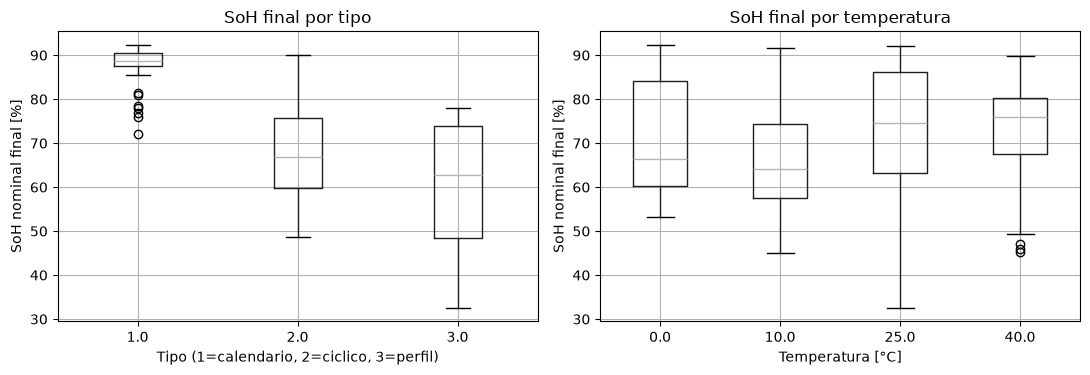

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
por_celda.boxplot(column="soh_fin", by="tipo", ax=axes[0])
axes[0].set_xlabel("Tipo (1=calendario, 2=ciclico, 3=perfil)")
axes[0].set_ylabel("SoH nominal final [%]")
axes[0].set_title("SoH final por tipo")
por_celda.boxplot(column="soh_fin", by="temp", ax=axes[1])
axes[1].set_xlabel("Temperatura [°C]")
axes[1].set_ylabel("SoH nominal final [%]")
axes[1].set_title("SoH final por temperatura")
plt.suptitle("")
plt.tight_layout()
plt.show()

In [10]:
cond_info = cons.groupby("condicion").first().reset_index()[
    ["condicion", "age_type", "age_temp", "age_soc",
     "age_chg_rate", "age_dischg_rate"]]
tabla = (por_celda.groupby("cond")
         .agg(celdas=("soh_fin", "size"),
              cu_media=("n_cu", "mean"),
              soh_fin_media=("soh_fin", "mean"))
         .reset_index().merge(cond_info, left_on="cond", right_on="condicion"))
print("76 condiciones (primeras 12):")
print(tabla.head(12).round(2).to_string(index=False))
print("...")
print("peor condicion (menor SoH final medio):")
print(tabla.nsmallest(3, "soh_fin_media").round(2).to_string(index=False))
print("mejor condicion (mayor SoH final medio):")
print(tabla.nlargest(3, "soh_fin_media").round(2).to_string(index=False))

76 condiciones (primeras 12):
 cond  celdas  cu_media  soh_fin_media  condicion  age_type  age_temp  age_soc  age_chg_rate  age_dischg_rate
    1       3      29.0          91.86          1       1.0       0.0     10.0           0.0              0.0
    2       3      29.0          90.39          2       1.0       0.0     50.0           0.0              0.0
    3       3      29.0          88.55          3       1.0       0.0     90.0           0.0              0.0
    4       3      29.0          88.79          4       1.0       0.0    100.0           0.0              0.0
    5       3      29.0          91.46          5       1.0      10.0     10.0           0.0              0.0
    6       3      29.0          90.32          6       1.0      10.0     50.0           0.0              0.0
    7       3      29.0          88.49          7       1.0      10.0     90.0           0.0              0.0
    8       3      29.0          87.92          8       1.0      10.0    100.0           0

## 5. Réplicas: ¿cuánto varía una celda de su gemela?

Cada condición tiene 3 réplicas (misma receta, celdas distintas). La
dispersión entre réplicas mide la variabilidad celda a celda que ningún
modelo basado solo en la condición puede explicar.

In [11]:
rep = por_celda.groupby("cond")["soh_fin"].agg(["mean", "std", "count"])
rep = rep.rename(columns={"mean": "soh_fin_media", "std": "soh_fin_std"})
print("desviacion tipica del SoH final dentro de la condicion (3 replicas):")
print(rep["soh_fin_std"].describe().round(2).to_string())
print()
print("condicion con mas dispersion entre replicas:")
print(rep.nlargest(3, "soh_fin_std").round(2).to_string())
print("condicion con menos dispersion:")
print(rep.nsmallest(3, "soh_fin_std").round(2).to_string())

desviacion tipica del SoH final dentro de la condicion (3 replicas):
count    76.00
mean      3.66
std       4.27
min       0.03
25%       0.50
50%       1.84
75%       5.56
max      15.70

condicion con mas dispersion entre replicas:
      soh_fin_media  soh_fin_std  count
cond                                   
59            65.40        15.70      3
52            71.71        14.03      3
70            64.23        13.64      3
condicion con menos dispersion:
      soh_fin_media  soh_fin_std  count
cond                                   
32            62.57         0.03      3
7             88.49         0.06      3
8             87.92         0.09      3


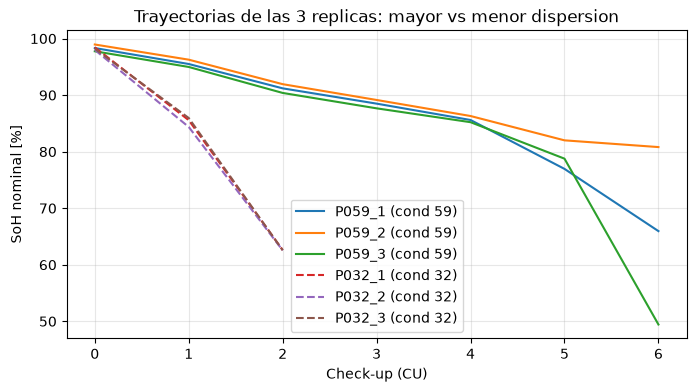

In [12]:
cond_max = rep["soh_fin_std"].idxmax()
cond_min = rep["soh_fin_std"].idxmin()
fig, ax = plt.subplots(figsize=(8, 4))
for cond, ls in [(cond_max, "-"), (cond_min, "--")]:
    for cid, g in cons[cons["condicion"] == cond].groupby("cell_id"):
        ax.plot(g["cu"], g["soh_nominal"], ls, lw=1.5,
                label=f"{cid} (cond {cond})")
ax.set_xlabel("Check-up (CU)")
ax.set_ylabel("SoH nominal [%]")
ax.set_title("Trayectorias de las 3 replicas: mayor vs menor dispersion")
ax.legend(); ax.grid(True, alpha=0.3)
plt.show()

## 6. Cobertura de EIS y PLS

Los archivos de impedancia y pulso existen para las 228 celdas. La EIS de
esta version (v2) ya trae todas las condiciones (P001–P076); no hace falta
el archivo corregido del addendum.

In [13]:
import glob
eis_files = sorted(glob.glob(str(REPO / "dataset" / "extraido" / "cell_eisv2" / "*.csv")))
pls_files = sorted(glob.glob(str(REPO / "dataset" / "extraido" / "cell_plsv2" / "*.csv")))
print("archivos EIS:", len(eis_files), "| archivos PLS:", len(pls_files))
for f in [eis_files[1], eis_files[100], eis_files[200]]:
    d = pd.read_csv(f, sep=";")
    print(Path(f).name, "->", d.shape)
for f in [pls_files[1], pls_files[100], pls_files[200]]:
    d = pd.read_csv(f, sep=";")
    print(Path(f).name, "->", d.shape)

archivos EIS: 240 | archivos PLS: 228
cell_eisv2_P000_0_S20_C01.csv -> (0, 22)
cell_eisv2_P030_2_S08_C05.csv -> (2784, 22)
cell_eisv2_P063_3_S18_C05.csv -> (8439, 22)
cell_plsv2_P001_2_S04_C09.csv -> (17690, 19)
cell_plsv2_P034_2_S08_C06.csv -> (9516, 19)
cell_plsv2_P067_3_S05_C01.csv -> (3477, 19)


## 7. Implicaciones para el diseño experimental

El diseño (`diseno-experimental-proyecto2-bateria-litio.tex`) fija: unidad =
celda, partición por celda (GroupKFold) + por condición (Leave-Conditions-Out)
+ corte temporal, historia mínima de 6 CU y corte C1 en 8 CU. ¿Cuántas celdas
llegan? ¿En cuántas se observa el RUL?

In [14]:
print("celdas con >= 6 CU (historia minima):", (por_celda["n_cu"] >= 6).sum(), "de 228")
print("celdas con >= 8 CU (llegan al corte C1):", (por_celda["n_cu"] >= 8).sum(), "de 228")
cruza80 = cons[cons["soh_nominal"] < 80].groupby("cell_id")["cu"].min()
cruza50 = cons[cons["soh_nominal"] < 50].groupby("cell_id")["cu"].min()
print("celdas que cruzan 80%% nominal (RUL a 80%% observable):", len(cruza80))
print("celdas que cruzan 50%% nominal (RUL a 50%% observable):", len(cruza50))
print("CU mediano del cruce 80%%:", cruza80.median(), "| del cruce 50%%:", cruza50.median())
print()
print("celdas que NO cruzan 80%%: su RUL a 80%% es censurado (no observado):",
      228 - len(cruza80))

celdas con >= 6 CU (historia minima): 180 de 228
celdas con >= 8 CU (llegan al corte C1): 164 de 228
celdas que cruzan 80%% nominal (RUL a 80%% observable): 166
celdas que cruzan 50%% nominal (RUL a 50%% observable): 15
CU mediano del cruce 80%%: 8.0 | del cruce 50%%: 20.0

celdas que NO cruzan 80%%: su RUL a 80%% es censurado (no observado): 62


**Conclusiones del AED 02**
1. Cobertura completa: 228 celdas, 76 condiciones × 3 réplicas, 4006 filas CU.
2. La fuga se confirma a escala (24 celdas, correlación 1,0): `cap_aged_est_Ah`
   queda fuera de las variables en todo el proyecto.
3. El SoH final varía mucho: media 70,9 % nominal; 163 celdas bajo 80 % y 15
   bajo 50 % al final. La degradación depende de la condición (tipo y temperatura).
4. La dispersión entre réplicas de la misma condición es la variabilidad que
   ningún modelo basado solo en la condición puede explicar: es el piso de error.
5. No todas las celdas llegan al corte (8 CU) ni cruzan los umbrales: el RUL
   es parcialmente censurado y hay que reportar cobertura, como fija el diseño.
6. EIS y PLS cubren las 228 celdas: son la primera mejora del modelo.